# ConvNeXt V2 — Co-designing ConvNets with Masked Autoencoders

**Paper:** Woo, S., Debnath, S., Hu, R., Chen, X., Liu, Z., Kweon, I. S., & Xie, S. (2023). ConvNeXt V2: Co-designing and Scaling ConvNets with Masked Autoencoders. *CVPR 2023*. https://arxiv.org/abs/2301.00808

**ConvNeXt V1:** Liu, Z., et al. (2022). A ConvNet for the 2020s. *CVPR 2022*. https://arxiv.org/abs/2201.03545

**Implementation:** `hale_core/nn/vision/cnn/convnext.py`

> ConvNeXt V2 modernises the CNN design space by adding Global Response Normalization (GRN) — a channel competition mechanism that prevents feature collapse during masked autoencoding pre-training.

> 📄 **Paper:** Woo et al. (2023). ConvNeXt V2: Co-designing and Scaling ConvNets with Masked Autoencoders. CVPR 2023.
> 🔗 **Link:** <https://arxiv.org/abs/2301.00808>
> 🧩 **Implementation:** `hale_core/nn/vision/cnn/convnext.py` (reproduced in full in §4 - runs with plain PyTorch)

**How this notebook is organised:** 1. paper & idea · 2. architecture diagrams (Mermaid, ASCII, matplotlib) ·
3. key ideas · 4. the full architecture in pure PyTorch · 5. build & run · 6. parameters vs paper & gradient flow ·
7. equivalence with the library · 8. feature maps · references.

## 2. Architecture diagram

Colours: <span style="color:#d48806">■ input</span> · <span style="color:#1f77b4">■ stages</span> ·
<span style="color:#8e44ad">■ blocks / operations</span> · <span style="color:#c0392b">■ outputs</span>.
(Mermaid renders on GitHub, in JupyterLab ≥ 4.1 and VS Code; an ASCII and a matplotlib version follow.)

```mermaid
flowchart TB
  IN["image (B, 3, 224, 224)"]:::io --> STEM["conv 4×4 /4 · LayerNorm"]:::stage
  STEM --> S["4 stages ×[3,3,9,3], widths 96·192·384·768"]:::stage --> GAP["avg pool · LayerNorm"]:::block --> OUT
  subgraph BLK["ConvNeXt V2 block"]
    direction LR
    X["x"] --> DW["7×7 depthwise"]:::block --> LN["LayerNorm"]:::block --> FC1["1×1 → 4C · GELU"]:::block --> GRN["Global Response Norm<br/>x·(1 + γ·N(x)) + β"]:::block --> FC2["1×1 → C"]:::block --> ADD(("+"))
    X --> ADD
  end
  S -.-> BLK
  MAE["FCMAE pre-training: sparse conv on masked patches"]:::block -.-> S
  OUT["BackboneOutput<br/>pooled_output (B, embed_dim)<br/>feature_maps finest → coarsest<br/>patch_tokens = None"]:::out
  classDef io fill:#fff7e6,stroke:#d48806,color:#222
  classDef stage fill:#eaf2fb,stroke:#1f77b4,color:#222
  classDef block fill:#f1e6f8,stroke:#8e44ad,color:#222
  classDef out fill:#fdecea,stroke:#c0392b,color:#222
```

## Architecture Overview

```
Input [B, 3, H, W]
       │
  ┌────▼──────────────────────────────────────────┐
  │  STEM: 4×4 Conv stride-4 + LayerNorm2d        │  → [B, C0, H/4, W/4]
  └───────────────────────────────────────────────┘
       │
  ┌────▼──────────────────────────────────────────┐
  │  STAGE 0: N0 × ConvNeXtV2Block                │  → [B, C0, H/4, W/4]
  └───────────────────────────────────────────────┘
       │ Downsample (LN2d + 2×2 stride-2)
  ┌────▼──────────────────────────────────────────┐
  │  STAGE 1: N1 × ConvNeXtV2Block                │  → [B, C1, H/8, W/8]
  └───────────────────────────────────────────────┘
       │ Downsample
  ┌────▼──────────────────────────────────────────┐
  │  STAGE 2: N2 × ConvNeXtV2Block                │  → [B, C2, H/16, W/16]
  └───────────────────────────────────────────────┘
       │ Downsample
  ┌────▼──────────────────────────────────────────┐
  │  STAGE 3: N3 × ConvNeXtV2Block                │  → [B, C3, H/32, W/32]
  └───────────────────────────────────────────────┘
       │
  AdaptiveAvgPool → LayerNorm → Dropout → [B, C3]

ConvNeXtV2Block (for channels C, drop_path p):
  x → DWConv 7×7 (groups=C) → transpose [B,C,H,W]→[B,H,W,C]
    → LayerNorm → Linear(4C) → GELU
    → GRN(4C)  ← THE V2 ADDITION
    → Linear(C) → transpose [B,H,W,C]→[B,C,H,W]
    → StochasticDepth → (+residual x)

GRN (Global Response Normalization):
  x: [B, H, W, C]
  gx = ‖x‖₂ over (H,W) → [B, 1, 1, C]  (global spatial L2 norm per channel)
  nx = gx / mean(gx, dim=C) + ε          (normalise across channels)
  out = gamma * (x * nx) + beta + x       (scale, shift, add identity)
```

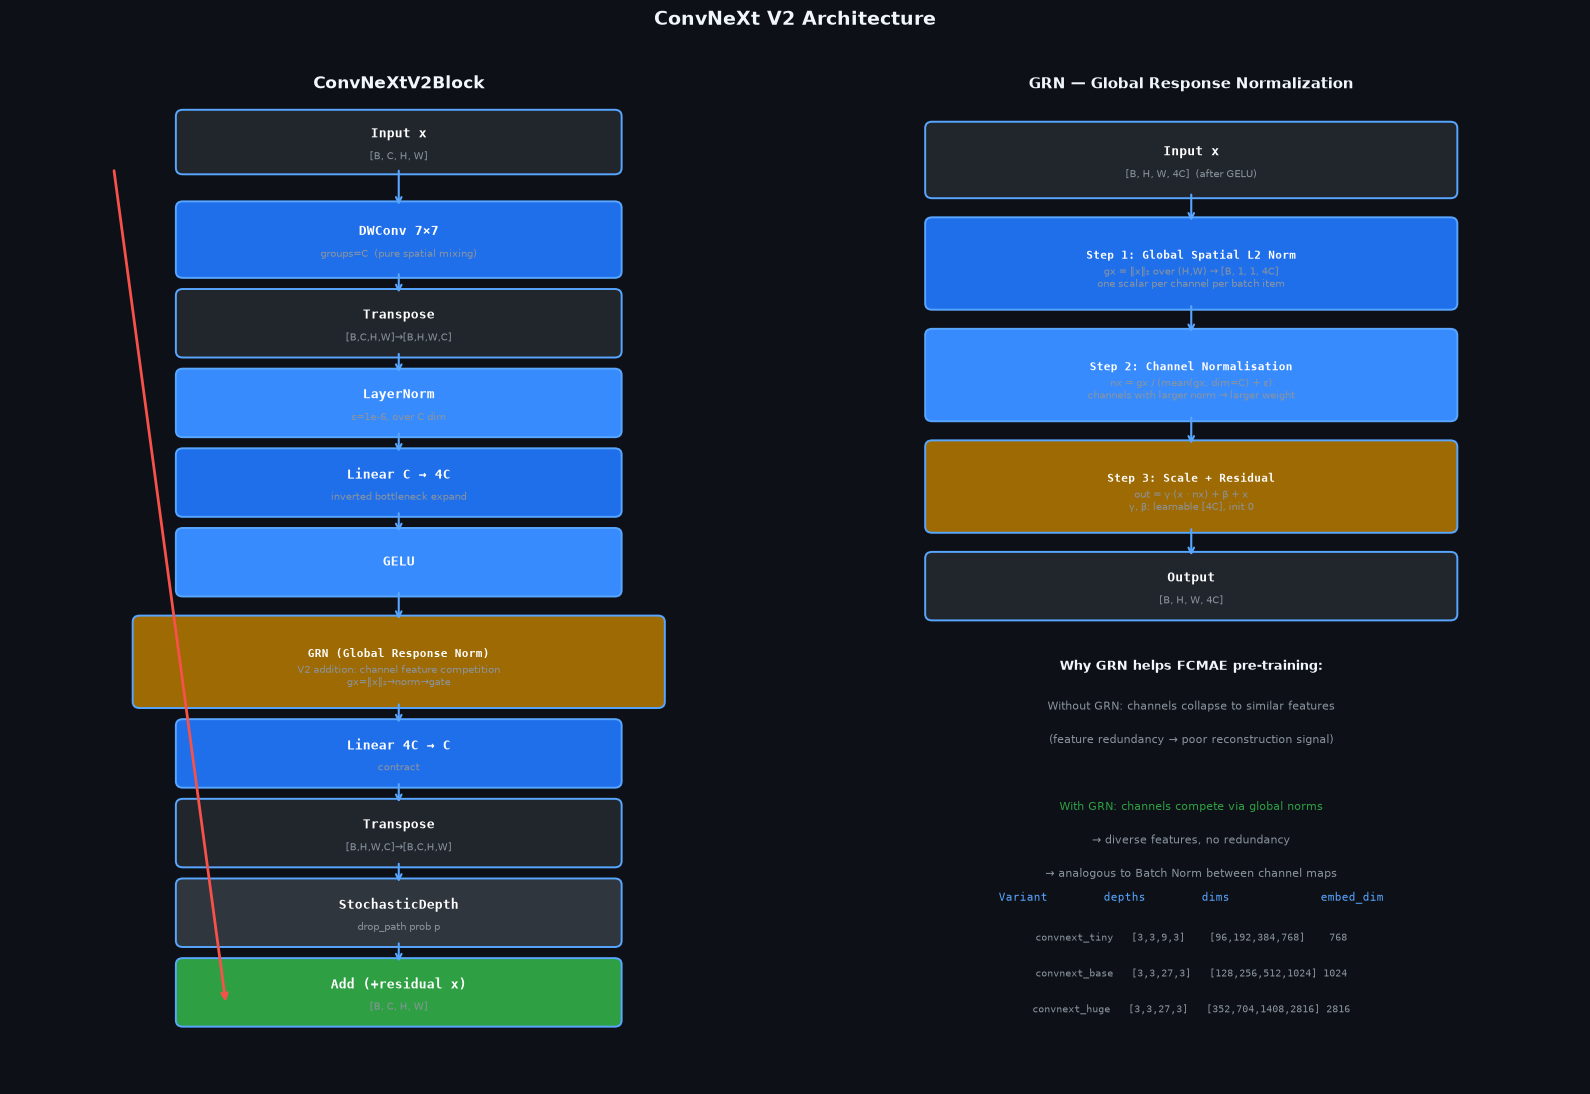

In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(16, 11))
fig.patch.set_facecolor('#0d1117')
for ax in axes:
    ax.set_facecolor('#0d1117')
    ax.axis('off')

def box(ax, x, y, w, h, text, sub='', fc='#1f6feb', fontsize=9):
    r = FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.08',
                        facecolor=fc, edgecolor='#58a6ff', lw=1.4)
    ax.add_patch(r)
    ax.text(x+w/2, y+h/2+(0.1 if sub else 0), text,
            ha='center', va='center', color='white',
            fontsize=fontsize, fontweight='bold', fontfamily='monospace')
    if sub:
        ax.text(x+w/2, y+h/2-0.18, sub, ha='center', va='center',
                color='#8b949e', fontsize=7)

def arr(ax, x1, y1, x2, y2):
    ax.annotate('', xy=(x2,y2), xytext=(x1,y1),
                arrowprops=dict(arrowstyle='->', color='#58a6ff', lw=1.5))

# ── LEFT: ConvNeXtV2Block internal flow ──────────────────────────────────────
ax = axes[0]
ax.set_xlim(0, 9)
ax.set_ylim(0, 13)
ax.text(4.5, 12.5, 'ConvNeXtV2Block', ha='center', color='#f0f6fc',
        fontsize=12, fontweight='bold')

box(ax, 2, 11.5, 5, 0.65, 'Input x', '[B, C, H, W]', fc='#21262d')
box(ax, 2, 10.2, 5, 0.8,  'DWConv 7×7', 'groups=C  (pure spatial mixing)', fc='#1f6feb')
arr(ax, 4.5, 11.5, 4.5, 11.0)
box(ax, 2, 9.2,  5, 0.7,  'Transpose', '[B,C,H,W]→[B,H,W,C]', fc='#21262d')
arr(ax, 4.5, 10.2, 4.5, 9.9)
box(ax, 2, 8.2,  5, 0.7,  'LayerNorm', 'ε=1e-6, over C dim', fc='#388bfd')
arr(ax, 4.5, 9.2, 4.5, 8.9)
box(ax, 2, 7.2,  5, 0.7,  'Linear C → 4C', 'inverted bottleneck expand', fc='#1f6feb')
arr(ax, 4.5, 8.2, 4.5, 7.9)
box(ax, 2, 6.2,  5, 0.7,  'GELU', '', fc='#388bfd')
arr(ax, 4.5, 7.2, 4.5, 6.9)

# GRN — highlighted differently
box(ax, 1.5, 4.8, 6, 1.0, 'GRN (Global Response Norm)', 'V2 addition: channel feature competition\ngx=‖x‖₂→norm→gate', fc='#9e6a03', fontsize=8)
arr(ax, 4.5, 6.2, 4.5, 5.8)

box(ax, 2, 3.8,  5, 0.7,  'Linear 4C → C', 'contract', fc='#1f6feb')
arr(ax, 4.5, 4.8, 4.5, 4.5)
box(ax, 2, 2.8,  5, 0.7,  'Transpose', '[B,H,W,C]→[B,C,H,W]', fc='#21262d')
arr(ax, 4.5, 3.8, 4.5, 3.5)
box(ax, 2, 1.8,  5, 0.7,  'StochasticDepth', 'drop_path prob p', fc='#30363d')
arr(ax, 4.5, 2.8, 4.5, 2.5)
box(ax, 2, 0.8,  5, 0.7,  'Add (+residual x)', '[B, C, H, W]', fc='#2ea043')
arr(ax, 4.5, 1.8, 4.5, 1.5)
# skip arrow
ax.annotate('', xy=(2.5, 1.0), xytext=(1.2, 11.5),
            arrowprops=dict(arrowstyle='->', color='#f85149', lw=2,
                            connectionstyle='arc3,rad=0.0'))

# ── RIGHT: GRN detail ────────────────────────────────────────────────────────
ax = axes[1]
ax.set_xlim(0, 9)
ax.set_ylim(0, 13)
ax.text(4.5, 12.5, 'GRN — Global Response Normalization', ha='center',
        color='#f0f6fc', fontsize=11, fontweight='bold')

box(ax, 1.5, 11.2, 6, 0.8, 'Input x', '[B, H, W, 4C]  (after GELU)', fc='#21262d')

# Step 1: global L2 norm
box(ax, 1.5, 9.8, 6, 1.0, 'Step 1: Global Spatial L2 Norm',
    'gx = ‖x‖₂ over (H,W) → [B, 1, 1, 4C]\none scalar per channel per batch item', fc='#1f6feb', fontsize=8)
arr(ax, 4.5, 11.2, 4.5, 10.8)

# Step 2: normalise across channels
box(ax, 1.5, 8.4, 6, 1.0, 'Step 2: Channel Normalisation',
    'nx = gx / (mean(gx, dim=C) + ε)\nchannels with larger norm → larger weight', fc='#388bfd', fontsize=8)
arr(ax, 4.5, 9.8, 4.5, 9.4)

# Step 3: gate + residual
box(ax, 1.5, 7.0, 6, 1.0, 'Step 3: Scale + Residual',
    'out = γ·(x · nx) + β + x\nγ, β: learnable [4C], init 0', fc='#9e6a03', fontsize=8)
arr(ax, 4.5, 8.4, 4.5, 8.0)

box(ax, 1.5, 5.9, 6, 0.7, 'Output', '[B, H, W, 4C]', fc='#21262d')
arr(ax, 4.5, 7.0, 4.5, 6.6)

# Explanation
ax.text(4.5, 5.2, 'Why GRN helps FCMAE pre-training:', ha='center',
        color='#f0f6fc', fontsize=9, fontweight='bold')

explanations = [
    'Without GRN: channels collapse to similar features',
    '(feature redundancy → poor reconstruction signal)',
    '',
    'With GRN: channels compete via global norms',
    '→ diverse features, no redundancy',
    '→ analogous to Batch Norm between channel maps',
]
for i, e in enumerate(explanations):
    color = '#2ea043' if 'With GRN' in e else '#8b949e'
    ax.text(4.5, 4.7 - i*0.42, e, ha='center', color=color, fontsize=8)

# Model size table
ax.text(4.5, 2.3, 'Variant        depths        dims             embed_dim', ha='center',
        color='#58a6ff', fontsize=8, fontfamily='monospace')
rows = [
    'convnext_tiny   [3,3,9,3]    [96,192,384,768]    768',
    'convnext_base   [3,3,27,3]   [128,256,512,1024] 1024',
    'convnext_huge   [3,3,27,3]   [352,704,1408,2816] 2816',
]
for i, r in enumerate(rows):
    ax.text(4.5, 1.8 - i*0.45, r, ha='center', color='#8b949e', fontsize=7.5, fontfamily='monospace')

plt.suptitle('ConvNeXt V2 Architecture', fontsize=14, color='#f0f6fc',
             fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()

## 3. Key ideas

## Key Innovations

### ConvNeXt V1 Modernisation Recipe (Liu et al. 2022)
Starting from ResNet-50, the V1 paper applied a series of ViT-inspired changes to a CNN:
- Stage ratio [1:1:3:1] → [1:1:3:1] (matching Swin)
- 3×3 conv → 7×7 depthwise conv (larger receptive field per layer)
- ReLU → GELU; BN → LayerNorm; more normalisation layers removed
- Inverted bottleneck (expand 4×) — opposite of Bottleneck
- Fewer activations: activation only after expand, not after each conv

Result: a plain CNN matching Swin Transformer accuracy at equivalent FLOPs.

### ConvNeXt V2 Additions (Woo et al. 2023)

**FCMAE Pre-training**: Apply masked autoencoding (like MAE for ViT) to the ConvNeXt backbone. Mask random 0.6 of patches at the pixel level, reconstruct from visible patches. However, applying FCMAE to V1 caused **feature collapse** — channels became redundant because there was nothing preventing them from learning the same features.

**Global Response Normalization (GRN)** is the fix:
- Compute per-channel global L2 norm (‖x‖₂ over H, W)
- Normalise these norms across channels
- Use normalised norms as gates → channels with larger global activation *enhance* themselves
- This is analogous to instance normalisation but operates on the *norms* (not the features directly)

**Why it works**: Channels that learn similar features will have similar global norms. GRN amplifies channels that stand out globally, effectively suppressing redundant channels. This encourages diverse feature learning, which is critical for reconstruction quality in FCMAE.

### Design Details
- **Channels-last convention**: after the 7×7 depthwise conv, the tensor is transposed to [B, H, W, C] for the LayerNorm and Linear layers, then transposed back. This avoids writing a custom BN wrapper and matches PyTorch's nn.LayerNorm interface.
- **LayerNorm2d**: a wrapper around `nn.LayerNorm` that handles the transpose (see lines 66–78 in `convnext.py`).
- **Stochastic depth**: rates distributed linearly from 0 at block 0 to `drop_path_rate` at the last block.
- **Stem**: 4×4 stride-4 conv (patch-like tokenisation), different from ResNet's 7×7+MaxPool. The stem is directly followed by LayerNorm2d.

## Component Walkthrough

### `GRN` (lines 83–115 in `convnext.py`)
```python
class GRN(nn.Module):
    def __init__(self, dim):
        self.gamma = nn.Parameter(torch.zeros(1, 1, 1, dim))  # init 0 → identity start
        self.beta  = nn.Parameter(torch.zeros(1, 1, 1, dim))

    def forward(self, x):  # x: [B, H, W, C]
        gx = x.norm(p=2, dim=(1, 2), keepdim=True)   # [B, 1, 1, C] global norms
        nx = gx / (gx.mean(dim=-1, keepdim=True) + 1e-6)  # normalise across C
        return self.gamma * (x * nx) + self.beta + x  # gate + residual
```

### `ConvNeXtV2Block` (lines 120–163 in `convnext.py`)
```python
def forward(self, x):           # x: [B, C, H, W]
    residual = x
    x = self.dwconv(x)          # 7×7 depthwise — spatial mixing
    x = x.permute(0, 2, 3, 1)  # channels-last for LN+Linear
    x = self.norm(x)            # LayerNorm over C
    x = self.pwconv1(x)         # Linear C→4C
    x = self.act(x)             # GELU
    x = self.grn(x)             # feature competition ← V2 key addition
    x = self.pwconv2(x)         # Linear 4C→C
    x = x.permute(0, 3, 1, 2)  # back to [B,C,H,W]
    return residual + self.drop_path(x)
```

### `ConvNeXtV2.forward` (lines 280–316 in `convnext.py`)
```python
def forward(self, x):
    x = self.stem(x)                # [B, dims[0], H/4, W/4]
    feature_maps = []
    for i, stage in enumerate(self.stages):
        x = stage(x)
        feature_maps.append(x)      # collect all 4 scale outputs
        if i < len(self.downsamples):
            x = self.downsamples[i](x)  # LN2d + 2×2 stride-2 conv
    pooled = self.norm(self.pool(feature_maps[-1]).flatten(1))
    return BackboneOutput(pooled_output=pooled, feature_maps=feature_maps)
```

## 4. The architecture in pure PyTorch

Below is the **complete implementation** used by HaleBlocks (`hale_core/nn/vision/cnn/convnext.py`), one top-level
definition per cell, with its original comments and docstrings. Only the `hale_core` imports were replaced by the
two foundation cells (the `BackboneOutput` / `BaseVisionBackbone` contract and a 10-line registry), so this notebook
runs anywhere PyTorch is installed. §7 checks it is bit-for-bit the library implementation.

<details><summary>Module docstring of <code>cnn/convnext.py</code></summary>

```text
ConvNeXt V2 Vision Backbones
=============================

Implements the ConvNeXt V2 family (Woo et al. 2023, "ConvNeXt V2: Co-designing and
Scaling ConvNets with Masked Autoencoders").

Architecture evolution
----------------------
ConvNeXt V1 (Liu et al. 2022, "A ConvNet for the 2020s"):
  - Modernised ConvNet: depthwise 7×7, inverted bottleneck, GeLU, LayerNorm.
  - Matched ViT in accuracy and design style while remaining a pure CNN.

ConvNeXt V2 adds:
  - FCMAE (Fully Convolutional Masked Autoencoder) pre-training paradigm.
  - Global Response Normalization (GRN): a channel feature competition mechanism
    analogous to SE (Squeeze-Excite) but operating globally on each channel.

ConvNeXtV2Block
---------------
  Input [B, C, H, W]
  1. Depthwise 7×7 conv (groups=C) — captures long-range spatial structure.
     Channels-first → channels-last transpose for LayerNorm efficiency.
  2. LayerNorm (channels-last, ε=1e-6).
  3. Pointwise Linear expand: C → 4C.
  4. GeLU activation.
  5. Global Response Normalization (GRN):
       x_norm = ‖x‖_2 across spatial dims → [B, 1, 1, C]
       x = x * (x_norm / mean(x_norm)) + bias   (gated by spatial norms)
     This penalises redundant channels and encourages diverse feature activations.
  6. Pointwise Linear contract: 4C → C.
  Residual add.

Stage downsampling
------------------
  Stem: 4×4 conv stride 4 → LayerNorm  (initial patch-like tokenization)
  Downsample between stages: LayerNorm + 2×2 conv stride 2.

Registered names and configs
-----------------------------
  convnext_tiny   — depths=[3,3,9,3],    dims=[96,192,384,768]
  convnext_small  — depths=[3,3,27,3],   dims=[96,192,384,768]
  convnext_base   — depths=[3,3,27,3],   dims=[128,256,512,1024]
  convnext_large  — depths=[3,3,27,3],   dims=[192,384,768,1536]
  convnext_xlarge — depths=[3,3,27,3],   dims=[256,512,1024,2048]
  convnext_huge   — depths=[3,3,27,3],   dims=[352,704,1408,2816]

Citations
---------
  Liu et al. (2022). A ConvNet for the 2020s. CVPR.
  Woo et al. (2023). ConvNeXt V2: Co-designing and Scaling ConvNets with MAE. CVPR.
```
</details>

In [2]:
from __future__ import annotations

# Everything below is plain PyTorch - no hale_core import is needed to run this notebook.
import math
from abc import ABC, abstractmethod
from copy import deepcopy
from dataclasses import dataclass, field
from typing import Any, Callable, Optional, Type, TypeVar, Union

import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
torch.set_num_threads(min(4, torch.get_num_threads()))
print("torch", torch.__version__)

torch 2.14.1


### 4.1 Foundation: the backbone contract (`base.py`) and a local registry

In [3]:
@dataclass
class BackboneOutput:
    """Standard output container for all vision backbones.

    Attributes
    ----------
    pooled_output:
        Global image representation after spatial pooling. Shape [B, embed_dim].
        Used by: classification heads, VLM projectors, action encoders.

    patch_tokens:
        Per-patch (or per-pixel) feature tokens BEFORE pooling.
        Shape [B, N, embed_dim] for ViT-style; None for pure CNNs.
        Used by: VLM cross-attention, dense grounding.

    feature_maps:
        Multi-scale spatial feature tensors, ordered finest → coarsest.
        Each element: [B, C_i, H/s_i, W/s_i] where s_i is the stride.
        Used by: FPN, BEV encoder, depth heads.

    attentions:
        Optional list of attention weight tensors from each transformer block.
        Used for interpretability (attention rollout, DINO self-supervised heads).
    """

    pooled_output: torch.Tensor                          # [B, embed_dim]
    patch_tokens:  Optional[torch.Tensor] = None        # [B, N, D] or None
    feature_maps:  list[torch.Tensor] = field(default_factory=list)  # multi-scale
    attentions:    Optional[list[torch.Tensor]] = None  # transformer attention maps


class BaseVisionBackbone(ABC, nn.Module):
    """Abstract base for all vision backbones.

    Subclasses MUST define:
      - arch_name  (str): human-readable identifier, e.g. "resnet50"
      - embed_dim  (int): dimension of pooled_output
      - feature_dims (list[int]): channel counts for each feature map scale
      - forward(x) -> BackboneOutput

    Args:
        img_size:   Expected input spatial resolution (height == width assumed).
        in_chans:   Number of input image channels (default 3 for RGB).
        drop_rate:  Dropout probability applied to the final pooled features.
        out_indices: Which multi-scale feature stages to include in BackboneOutput.
                     E.g. [0, 1, 2, 3] returns all four scales; [2, 3] returns
                     only the two coarsest.  Default returns all available.
    """

    # ── Class-level metadata — override in each subclass ─────────────────────
    arch_name:    str        = "base"
    embed_dim:    int        = 0
    feature_dims: list[int] = []   # channel counts per stage, finest→coarsest

    def __init__(
        self,
        img_size:    int        = 224,
        in_chans:    int        = 3,
        drop_rate:   float      = 0.0,
        out_indices: list[int] | None = None,
    ) -> None:
        super().__init__()
        self.img_size    = img_size
        self.in_chans    = in_chans
        self.drop_rate   = drop_rate
        self.out_indices = out_indices  # None = return all stages

    @abstractmethod
    def forward(self, x: torch.Tensor) -> BackboneOutput:
        """Run the backbone on a batch of images.

        Args:
            x: Float32 tensor of shape [B, in_chans, H, W].
               Typically ImageNet-normalised (mean=[0.485,0.456,0.406],
               std=[0.229,0.224,0.225]).

        Returns:
            BackboneOutput with pooled_output, patch_tokens, feature_maps.
        """
        ...

    # ── Convenience helpers ───────────────────────────────────────────────────

    def num_parameters(self, trainable_only: bool = False) -> int:
        """Count model parameters.

        Args:
            trainable_only: If True, count only parameters with requires_grad=True.

        Returns:
            Integer parameter count.
        """
        params = self.parameters()
        if trainable_only:
            params = (p for p in params if p.requires_grad)
        return sum(p.numel() for p in params)

    def freeze_all(self) -> None:
        """Freeze all parameters (no gradient computation).

        Useful when using the backbone as a frozen feature extractor
        inside a VLM or action decoder that only trains the head.
        """
        for p in self.parameters():
            p.requires_grad_(False)

    def unfreeze_all(self) -> None:
        """Unfreeze all parameters."""
        for p in self.parameters():
            p.requires_grad_(True)

    def freeze_up_to_stage(self, stage: int) -> None:
        """Freeze all stages from 0 up to and including `stage`.

        Useful for fine-tuning: freeze the early feature extractor stages
        and only fine-tune the later stages.  The exact meaning of "stage"
        is backbone-specific; see each subclass's docstring.

        Args:
            stage: Stage index (0-based).  Stages 0..stage are frozen.
        """
        raise NotImplementedError(
            f"{self.__class__.__name__} does not implement freeze_up_to_stage()"
        )

    def __repr__(self) -> str:
        return (
            f"{self.__class__.__name__}("
            f"arch={self.arch_name}, "
            f"embed_dim={self.embed_dim}, "
            f"img_size={self.img_size}, "
            f"params={self.num_parameters():,})"
        )

In [4]:
# A minimal stand-in for hale_core.nn.vision.registry: same decorator name and behaviour, so the
# library source below runs unchanged. Re-registration is allowed so cells can be re-run.
_VISION_BACKBONES: dict[str, type] = {}
T = TypeVar("T")


def register_vision_backbone(name: str) -> Callable[[T], T]:
    """Class decorator: store ``cls`` under ``name`` (lower-case)."""
    def decorator(cls: T) -> T:
        _VISION_BACKBONES[name.lower()] = cls
        return cls
    return decorator


def build_vision_backbone(name: str, **kwargs: Any) -> "BaseVisionBackbone":
    """Instantiate a backbone registered in this notebook."""
    return _VISION_BACKBONES[name.lower()](**kwargs)


def list_vision_backbones() -> list[str]:
    return sorted(_VISION_BACKBONES)

### 4.2 `cnn/convnext.py`, definition by definition

**`LayerNorm2d`** - LayerNorm adapted for channels-first (B, C, H, W) spatial tensors.

In [5]:
class LayerNorm2d(nn.LayerNorm):
    """LayerNorm adapted for channels-first (B, C, H, W) spatial tensors.

    PyTorch's nn.LayerNorm expects the normalised dims to be the last dims.
    This wrapper transposes to channels-last before normalising, then transposes back.
    This is the standard approach used by ConvNeXt and many modern CNNs.
    """

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x: [B, C, H, W]
        x = x.permute(0, 2, 3, 1)          # → [B, H, W, C]
        x = super().forward(x)              # LayerNorm over last dim C
        return x.permute(0, 3, 1, 2)       # → [B, C, H, W]

**`GRN`** - Global Response Normalization (GRN) — the key addition in ConvNeXt V2.

In [6]:
class GRN(nn.Module):
    """Global Response Normalization (GRN) — the key addition in ConvNeXt V2.

    GRN introduces cross-channel feature competition: channels with large global
    norms suppress channels with small global norms.  This discourages feature
    collapse (redundant channels learning the same thing) during masked autoencoding.

    Formulation (Woo et al. 2023, Eq. 1–3):
        gx = ‖x‖₂ over H, W dims          → [B, 1, 1, C]  (global spatial norm)
        nx = gx / E[gx]                    → normalised norms (E over C)
        output = x * nx + gamma * x + beta
    where gamma and beta are learned per-channel parameters (shape [C]).

    Args:
        dim: Number of feature channels (C).

    Shape:
        Input / Output: [B, H, W, C]  (channels-last convention inside blocks)
    """

    def __init__(self, dim: int) -> None:
        super().__init__()
        # Learnable scale and bias initialised to 0 (start as identity)
        self.gamma = nn.Parameter(torch.zeros(1, 1, 1, dim))
        self.beta  = nn.Parameter(torch.zeros(1, 1, 1, dim))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Global spatial L2 norm per channel: [B, 1, 1, C]
        gx = x.norm(p=2, dim=(1, 2), keepdim=True)
        # Normalise across the channel dimension
        nx = gx / (gx.mean(dim=-1, keepdim=True) + 1e-6)
        # Scale and shift
        return self.gamma * (x * nx) + self.beta + x

**`ConvNeXtV2Block`** - Single ConvNeXt V2 residual block.

In [7]:
class ConvNeXtV2Block(nn.Module):
    """Single ConvNeXt V2 residual block.

    Sequence: DWConv → LayerNorm → Linear(4x expand) → GeLU → GRN → Linear(contract)
    with a residual connection.  All linear ops are implemented as pointwise 1×1
    convolutions via nn.Linear on the transposed tensor (channels-last) for clarity.

    Args:
        dim:        Number of input (and output) channels.
        drop_path:  Stochastic depth drop probability (0 = disabled).
    """

    def __init__(self, dim: int, drop_path: float = 0.0) -> None:
        super().__init__()

        # Depthwise 7×7 conv — processes spatial context within each channel
        self.dwconv = nn.Conv2d(dim, dim, kernel_size=7, padding=3, groups=dim)
        # LayerNorm in channels-last space (after transpose)
        self.norm  = nn.LayerNorm(dim, eps=1e-6)
        # Inverted bottleneck: expand 4× for more capacity
        self.pwconv1 = nn.Linear(dim, 4 * dim)
        self.act     = nn.GELU()
        # GRN — the V2-specific feature competition layer
        self.grn     = GRN(4 * dim)
        # Contract back to dim
        self.pwconv2 = nn.Linear(4 * dim, dim)

        # Stochastic depth: randomly drops the entire block during training
        # (equivalent to randomly skipping the residual branch)
        self.drop_path = StochasticDepth(drop_path) if drop_path > 0.0 else nn.Identity()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        residual = x

        x = self.dwconv(x)                  # [B, C, H, W] — depthwise spatial conv
        x = x.permute(0, 2, 3, 1)          # → [B, H, W, C] for LayerNorm + Linear
        x = self.norm(x)
        x = self.pwconv1(x)                 # [B, H, W, 4C]
        x = self.act(x)
        x = self.grn(x)                     # feature competition
        x = self.pwconv2(x)                 # [B, H, W, C]
        x = x.permute(0, 3, 1, 2)          # → [B, C, H, W]

        return residual + self.drop_path(x)

**`StochasticDepth`** - Stochastic depth regularisation (Huang et al. 2016).

In [8]:
class StochasticDepth(nn.Module):
    """Stochastic depth regularisation (Huang et al. 2016).

    Randomly drops the entire forward path of a block during training,
    equivalent to randomly shortening the effective depth of the network.
    At inference, acts as identity scaled by survival probability.

    Args:
        drop_prob: Probability of dropping (zeroing) the block output.
    """

    def __init__(self, drop_prob: float) -> None:
        super().__init__()
        self.drop_prob = drop_prob

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if not self.training or self.drop_prob == 0.0:
            return x
        keep_prob = 1.0 - self.drop_prob
        # Random binary mask: shape [B, 1, 1, 1] — drops entire samples in the batch
        shape = (x.shape[0],) + (1,) * (x.ndim - 1)
        noise = torch.rand(shape, dtype=x.dtype, device=x.device)
        noise = torch.floor(noise + keep_prob)
        # Scale by 1/keep_prob to maintain expected value (like dropout)
        return x * noise / keep_prob

**`ConvNeXtV2`** - Full ConvNeXt V2 feature extractor.

In [9]:
class ConvNeXtV2(BaseVisionBackbone):
    """Full ConvNeXt V2 feature extractor.

    Builds 4 stages of ConvNeXtV2Block with progressive downsampling,
    returning 4-scale feature maps for FPN/detection heads and a global
    pooled embedding for classification/VLM heads.

    Args:
        depths:      Number of blocks in each of the 4 stages.
        dims:        Channel dimensions at each of the 4 stages.
        drop_path_rate: Maximum stochastic depth rate (linearly distributed).
        img_size:    Expected input spatial resolution.
        in_chans:    Input image channels (default 3).
        drop_rate:   Dropout after global pool.
        out_indices: Which stage outputs to include in feature_maps.
    """

    def __init__(
        self,
        depths:          list[int],
        dims:            list[int],
        drop_path_rate:  float = 0.0,
        img_size:        int   = 224,
        in_chans:        int   = 3,
        drop_rate:       float = 0.0,
        out_indices:     list[int] | None = None,
    ) -> None:
        super().__init__(img_size=img_size, in_chans=in_chans, drop_rate=drop_rate, out_indices=out_indices)

        self.embed_dim   = dims[-1]
        self.feature_dims = list(dims)

        # Linearly distribute drop_path rates across all blocks
        total_blocks = sum(depths)
        dp_rates = [
            x.item()
            for x in torch.linspace(0, drop_path_rate, total_blocks)
        ]

        # ── Stem: patch-like tokenisation (4×4 stride-4) ─────────────────────
        # Unlike ViT's patch embedding, this is a simple large-stride conv + LN.
        # Reduces [B, 3, H, W] → [B, dims[0], H/4, W/4]
        self.stem = nn.Sequential(
            nn.Conv2d(in_chans, dims[0], kernel_size=4, stride=4),
            LayerNorm2d(dims[0], eps=1e-6),
        )

        # ── 4 main stages ─────────────────────────────────────────────────────
        self.stages = nn.ModuleList()
        block_idx = 0
        for i, (depth, dim) in enumerate(zip(depths, dims)):
            blocks = [
                ConvNeXtV2Block(dim, drop_path=dp_rates[block_idx + j])
                for j in range(depth)
            ]
            self.stages.append(nn.Sequential(*blocks))
            block_idx += depth

        # ── Downsampling between stages (stages 0→1, 1→2, 2→3) ───────────────
        # LayerNorm + 2×2 stride-2 conv halves resolution and doubles channels
        self.downsamples = nn.ModuleList([
            nn.Sequential(
                LayerNorm2d(dims[i], eps=1e-6),
                nn.Conv2d(dims[i], dims[i + 1], kernel_size=2, stride=2),
            )
            for i in range(len(dims) - 1)
        ])

        # ── Head ─────────────────────────────────────────────────────────────
        self.norm    = nn.LayerNorm(dims[-1], eps=1e-6)
        self.pool    = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(drop_rate) if drop_rate > 0.0 else nn.Identity()

        self._init_weights()

    def _init_weights(self) -> None:
        """Truncated normal for conv/linear; const for norm layers."""
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.Linear)):
                nn.init.trunc_normal_(m.weight, std=0.02)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def forward(self, x: torch.Tensor) -> BackboneOutput:
        """Forward pass returning multi-scale feature maps and pooled embedding.

        Args:
            x: [B, in_chans, H, W]

        Returns:
            BackboneOutput:
              pooled_output — [B, dims[-1]]
              patch_tokens  — None
              feature_maps  — 4 tensors at strides 4, 8, 16, 32
        """
        x = self.stem(x)   # [B, dims[0], H/4, W/4]

        feature_maps = []
        for i, stage in enumerate(self.stages):
            x = stage(x)
            feature_maps.append(x)          # collect output of each stage
            if i < len(self.downsamples):   # downsample between stages (not after last)
                x = self.downsamples[i](x)

        # Global pooled embedding
        pooled = self.pool(feature_maps[-1]).flatten(1)  # [B, dims[-1]]
        pooled = self.norm(pooled)
        pooled = self.dropout(pooled)

        # Select requested scales
        all_maps = feature_maps
        if self.out_indices is not None:
            all_maps = [feature_maps[i] for i in self.out_indices]

        return BackboneOutput(
            pooled_output=pooled,
            patch_tokens=None,
            feature_maps=all_maps,
            attentions=None,
        )

    def freeze_up_to_stage(self, stage: int) -> None:
        """Freeze stem and stages 0 through `stage` inclusive.

        Args:
            stage: 0-based index in [0, 3].
        """
        if stage < 0 or stage > 3:
            raise ValueError(f"stage must be in [0, 3], got {stage}")
        for p in self.stem.parameters():
            p.requires_grad_(False)
        for i in range(stage + 1):
            for p in self.stages[i].parameters():
                p.requires_grad_(False)
            if i < len(self.downsamples):
                for p in self.downsamples[i].parameters():
                    p.requires_grad_(False)

**`ConvNeXtTiny`** - ConvNeXt V2 Tiny: depths=[3,3,9,3], dims=[96,192,384,768].

In [10]:
@register_vision_backbone("convnext_tiny")
class ConvNeXtTiny(ConvNeXtV2):
    """ConvNeXt V2 Tiny: depths=[3,3,9,3], dims=[96,192,384,768]."""
    arch_name    = "convnext_tiny"
    embed_dim    = 768
    feature_dims = [96, 192, 384, 768]

    def __init__(self, **kwargs) -> None:
        super().__init__(depths=[3, 3, 9, 3], dims=[96, 192, 384, 768], **kwargs)

**`ConvNeXtSmall`** - ConvNeXt V2 Small: depths=[3,3,27,3], dims=[96,192,384,768].

In [11]:
@register_vision_backbone("convnext_small")
class ConvNeXtSmall(ConvNeXtV2):
    """ConvNeXt V2 Small: depths=[3,3,27,3], dims=[96,192,384,768]."""
    arch_name    = "convnext_small"
    embed_dim    = 768
    feature_dims = [96, 192, 384, 768]

    def __init__(self, **kwargs) -> None:
        super().__init__(depths=[3, 3, 27, 3], dims=[96, 192, 384, 768], **kwargs)

**`ConvNeXtBase`** - ConvNeXt V2 Base: depths=[3,3,27,3], dims=[128,256,512,1024].

In [12]:
@register_vision_backbone("convnext_base")
class ConvNeXtBase(ConvNeXtV2):
    """ConvNeXt V2 Base: depths=[3,3,27,3], dims=[128,256,512,1024]."""
    arch_name    = "convnext_base"
    embed_dim    = 1024
    feature_dims = [128, 256, 512, 1024]

    def __init__(self, **kwargs) -> None:
        super().__init__(depths=[3, 3, 27, 3], dims=[128, 256, 512, 1024], **kwargs)

**`ConvNeXtLarge`** - ConvNeXt V2 Large: depths=[3,3,27,3], dims=[192,384,768,1536].

In [13]:
@register_vision_backbone("convnext_large")
class ConvNeXtLarge(ConvNeXtV2):
    """ConvNeXt V2 Large: depths=[3,3,27,3], dims=[192,384,768,1536]."""
    arch_name    = "convnext_large"
    embed_dim    = 1536
    feature_dims = [192, 384, 768, 1536]

    def __init__(self, **kwargs) -> None:
        super().__init__(depths=[3, 3, 27, 3], dims=[192, 384, 768, 1536], **kwargs)

**`ConvNeXtXLarge`** - ConvNeXt V2 XLarge: depths=[3,3,27,3], dims=[256,512,1024,2048].

In [14]:
@register_vision_backbone("convnext_xlarge")
class ConvNeXtXLarge(ConvNeXtV2):
    """ConvNeXt V2 XLarge: depths=[3,3,27,3], dims=[256,512,1024,2048]."""
    arch_name    = "convnext_xlarge"
    embed_dim    = 2048
    feature_dims = [256, 512, 1024, 2048]

    def __init__(self, **kwargs) -> None:
        super().__init__(depths=[3, 3, 27, 3], dims=[256, 512, 1024, 2048], **kwargs)

**`ConvNeXtHuge`** - ConvNeXt V2 Huge: depths=[3,3,27,3], dims=[352,704,1408,2816].

In [15]:
@register_vision_backbone("convnext_huge")
class ConvNeXtHuge(ConvNeXtV2):
    """ConvNeXt V2 Huge: depths=[3,3,27,3], dims=[352,704,1408,2816]."""
    arch_name    = "convnext_huge"
    embed_dim    = 2816
    feature_dims = [352, 704, 1408, 2816]

    def __init__(self, **kwargs) -> None:
        super().__init__(depths=[3, 3, 27, 3], dims=[352, 704, 1408, 2816], **kwargs)

## 5. Build and run it

Every variant defined above is now in the notebook's registry. Build the demo variants, run a batch through them and
check the `BackboneOutput` contract: `pooled_output (B, embed_dim)`, multi-scale `feature_maps` (finest → coarsest)
and, for transformers, `patch_tokens`. The **stride** of each map is `input size / map size`.

In [16]:
DEMOS = {"convnext_tiny": 28.6}          # variant -> paper parameter count (M, incl. 1000-class head)
IMG = 224
print("variants defined in this notebook:", list_vision_backbones())

x = torch.randn(2, 3, IMG, IMG)
models = {}
for name in DEMOS:
    torch.manual_seed(0)
    model = build_vision_backbone(name, img_size=IMG).eval()
    models[name] = model
    with torch.no_grad():
        out = model(x)
    print(f"\n{name}  ({type(model).__name__})")
    print(f"  pooled_output : {tuple(out.pooled_output.shape)}   embed_dim = {model.embed_dim}")
    if out.patch_tokens is not None:
        print(f"  patch_tokens  : {tuple(out.patch_tokens.shape)}")
    for i, fm in enumerate(out.feature_maps):
        print(f"  feature_map {i}: {tuple(fm.shape)}   stride {IMG / fm.shape[-1]:.0f}")
    assert out.pooled_output.shape == (2, model.embed_dim)

variants defined in this notebook: ['convnext_base', 'convnext_huge', 'convnext_large', 'convnext_small', 'convnext_tiny', 'convnext_xlarge']



convnext_tiny  (ConvNeXtTiny)
  pooled_output : (2, 768)   embed_dim = 768
  feature_map 0: (2, 96, 56, 56)   stride 4
  feature_map 1: (2, 192, 28, 28)   stride 8
  feature_map 2: (2, 384, 14, 14)   stride 16
  feature_map 3: (2, 768, 7, 7)   stride 32


## 6. Parameter count vs the paper

Papers report parameters *including* the 1000-class classifier; the backbone has none, so `+ head` adds
`embed_dim × 1000 + 1000`. ✅ = within 5 % of the paper.

In [17]:
print(f"{'variant':20s} {'backbone':>10s} {'+ head':>10s} {'paper':>8s} {'ratio':>7s}")
for name, paper in DEMOS.items():
    model = models[name]
    p = sum(t.numel() for t in model.parameters()) / 1e6
    with_head = p + (model.embed_dim * 1000 + 1000) / 1e6
    if paper is None:
        print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {'n/a':>8s}")
        continue
    ratio = with_head / paper
    print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {paper:7.1f}M {ratio:7.2f}  {'✅' if abs(ratio - 1) < 0.05 else '⚠️ differs from paper'}")

variant                backbone     + head    paper   ratio
convnext_tiny            27.87M     28.64M    28.6M    1.00  ✅


### Gradient flow

A backbone is only useful if every parameter is trained. Back-propagate a scalar through the pooled output **and**
all feature maps and list parameters that receive no gradient.

In [18]:
for name, model in models.items():
    model.train().zero_grad()
    out = model(torch.randn(2, 3, IMG, IMG))
    loss = out.pooled_output.square().mean() + sum(fm.square().mean() for fm in out.feature_maps)
    loss.backward()
    dead = [n for n, p in model.named_parameters() if p.requires_grad and (p.grad is None or not torch.isfinite(p.grad).all())]
    total = sum(1 for p in model.parameters() if p.requires_grad)
    print(f"{name}: loss {loss.item():.4f} | {total - len(dead)}/{total} parameter tensors receive a finite gradient")
    if dead:
        print("   no gradient:", dead[:8], "..." if len(dead) > 8 else "")
    model.eval()

convnext_tiny: loss 3.7461 | 198/198 parameter tensors receive a finite gradient


## 7. Same code as the library?

If `hale_core` (HaleBlocks) is installed, build the library model, copy this notebook's weights into it with
`strict=True` (same parameter names and shapes) and compare outputs. A difference of `0.0` proves the code above *is*
the library implementation. Without HaleBlocks installed the check is skipped - the notebook itself is unaffected.

In [19]:
try:
    import logging, importlib
    logging.disable(logging.CRITICAL)
    try:
        from loguru import logger as _lg; _lg.remove()
    except ImportError:
        pass
    from hale_core.nn.vision.registry import build_vision_backbone as build_library_backbone
except ImportError:
    build_library_backbone = None
    print("hale_core is not installed here - skipping the library equivalence check.")

if build_library_backbone is not None:
    for name, model in models.items():
        lib = build_library_backbone(name, img_size=IMG).eval()
        lib.load_state_dict(model.state_dict(), strict=True)
        with torch.no_grad():
            a, b = model(x), lib(x)
        diff = max([(a.pooled_output - b.pooled_output).abs().max().item()] +
                   [(fa - fb).abs().max().item() for fa, fb in zip(a.feature_maps, b.feature_maps)])
        print(f"{name}: notebook vs hale_core max |diff| = {diff:.1e}  {'✅ identical' if diff == 0 else ''}")

convnext_tiny: notebook vs hale_core max |diff| = 0.0e+00  ✅ identical


## 8. What the feature maps look like

A synthetic image (a few coloured shapes) through the first demo variant: the channel-mean activation of every
feature map. Early maps keep edges at high resolution, late maps are coarse and semantic.

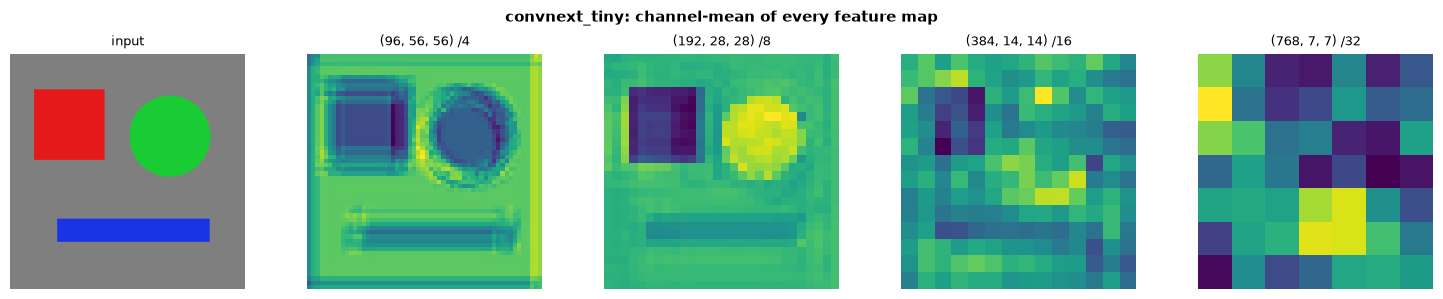

In [20]:
import matplotlib.pyplot as plt

def synthetic_image(size: int) -> torch.Tensor:
    """(1, 3, size, size) image with a red square, a green disc and a blue bar on grey."""
    yy, xx = torch.meshgrid(torch.linspace(0, 1, size), torch.linspace(0, 1, size), indexing="ij")
    img = torch.full((3, size, size), 0.5)
    sq = (xx > 0.1) & (xx < 0.4) & (yy > 0.15) & (yy < 0.45)
    disc = (xx - 0.68) ** 2 + (yy - 0.35) ** 2 < 0.03
    bar = (xx > 0.2) & (xx < 0.85) & (yy > 0.7) & (yy < 0.8)
    for mask, rgb in ((sq, (0.9, 0.1, 0.1)), (disc, (0.1, 0.8, 0.2)), (bar, (0.1, 0.2, 0.9))):
        for c in range(3):
            img[c][mask] = rgb[c]
    mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
    std = torch.tensor([0.229, 0.224, 0.225])[:, None, None]
    return ((img - mean) / std)[None], img

name = next(iter(models))
inp, raw = synthetic_image(IMG)
with torch.no_grad():
    maps = models[name](inp).feature_maps
fig, axes = plt.subplots(1, len(maps) + 1, figsize=(3 * (len(maps) + 1), 3), facecolor="white")
axes[0].imshow(raw.permute(1, 2, 0)); axes[0].set_title("input", fontsize=9)
for ax, fm in zip(axes[1:], maps):
    ax.imshow(fm[0].mean(0), cmap="viridis")
    ax.set_title(f"{tuple(fm.shape[1:])} /{IMG // fm.shape[-1]}", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.suptitle(f"{name}: channel-mean of every feature map", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

## 9. Experiments from the original walkthrough

The original notebook's hands-on cells, now running on the implementation defined in §4 (they used to import
`hale_core` through a relative `sys.path`, which only worked inside the HaleBlocks repo).

In [21]:
import sys
import numpy as np
import matplotlib.pyplot as plt

In [22]:
import sys

import torch

x = torch.randn(1, 3, 224, 224)

for name in ['convnext_tiny', 'convnext_base', 'convnext_large']:
    bb = build_vision_backbone(name, img_size=224)
    bb.eval()
    with torch.no_grad():
        out = bb(x)
    print(f'{name:18s}  embed={out.pooled_output.shape[-1]}')
    print(f'  feature_maps: {[tuple(f.shape) for f in out.feature_maps]}')
    print(f'  params: {bb.num_parameters():,}')
    print()

convnext_tiny       embed=768
  feature_maps: [(1, 96, 56, 56), (1, 192, 28, 28), (1, 384, 14, 14), (1, 768, 7, 7)]
  params: 27,866,496



convnext_base       embed=1024
  feature_maps: [(1, 128, 56, 56), (1, 256, 28, 28), (1, 512, 14, 14), (1, 1024, 7, 7)]
  params: 87,692,800



convnext_large      embed=1536
  feature_maps: [(1, 192, 56, 56), (1, 384, 28, 28), (1, 768, 14, 14), (1, 1536, 7, 7)]
  params: 196,419,840



## References

1. **[Primary]** Woo, S., Debnath, S., Hu, R., Chen, X., Liu, Z., Kweon, I. S., & Xie, S. (2023). **ConvNeXt V2: Co-designing and Scaling ConvNets with Masked Autoencoders**. *CVPR 2023*. https://arxiv.org/abs/2301.00808

2. Liu, Z., Mao, H., Wu, C.-Y., Feichtenhofer, C., Darrell, T., & Xie, S. (2022). **A ConvNet for the 2020s (ConvNeXt V1)**. *CVPR 2022*. https://arxiv.org/abs/2201.03545

3. He, K., Chen, X., Xie, S., Li, Y., Dollár, P., & Girshick, R. (2022). **Masked Autoencoders Are Scalable Vision Learners (MAE)**. *CVPR 2022*. — The MAE pre-training paradigm that FCMAE is based on.

4. Liu, Z., et al. (2021). **Swin Transformer**. *ICCV 2021*. — The ViT-based architecture that ConvNeXt competed against, providing the design blueprint.

5. Huang, G., Sun, Y., Liu, Z., Sedra, D., & Weinberger, K. Q. (2016). **Deep Networks with Stochastic Depth**. *ECCV 2016*. — Stochastic depth regularisation used in ConvNeXt V2.